Experiment 4: Autoencoder for Anomaly Detection
Aim: Train an autoencoder on normal ECG signals and use reconstruction error to identify anomalous signals.

Dataset: ECG dataset specified in the lab manual. The last column is the label: 1 = normal, 0 = anomaly.

1. Import libraries and load the dataset

In [1]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('TensorFlow:', tf.__version__)

TensorFlow: 2.21.0


In [2]:
url = 'https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv'
csv_path = pathlib.Path('ecg.csv')

if not csv_path.exists():
    df = pd.read_csv(url, header=None)
    df.to_csv(csv_path, index=False, header=False)
else:
    df = pd.read_csv(csv_path, header=None)

X = df.iloc[:, :-1].to_numpy(dtype='float32')
y = df.iloc[:, -1].to_numpy(dtype='int32')

print('Dataset shape:', df.shape)
print('Feature shape:', X.shape)
print('Labels and counts:', dict(zip(*np.unique(y, return_counts=True))))

Dataset shape: (4998, 141)
Feature shape: (4998, 140)
Labels and counts: {np.int32(0): np.int64(2079), np.int32(1): np.int64(2919)}


2. Split, select normal training data, and scale
The scaler is fitted only on normal training examples. This keeps test data out of the fitting step.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Novelty detection: fit the autoencoder using normal training ECGs only.
X_train_normal = X_train[y_train == 1]

scaler = MinMaxScaler()
X_train_normal_scaled = scaler.fit_transform(X_train_normal).astype('float32')
X_test_scaled = scaler.transform(X_test).astype('float32')

print('Normal training examples:', X_train_normal_scaled.shape[0])
print('Test examples:', X_test_scaled.shape[0])
print('Features per ECG:', X_train_normal_scaled.shape[1])

Normal training examples: 2335
Test examples: 1000
Features per ECG: 140


3. Build and train the autoencoder

The encoder compresses each ECG into a smaller latent representation. The decoder reconstructs the original feature vector. The model is trained to reproduce normal examples.

In [4]:
class AutoEncoder(tf.keras.Model):
    def __init__(self, input_dim):
        super().__init__()
        self.encoder = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(input_dim,)),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(16, activation='relu'),
            tf.keras.layers.Dense(8, activation='relu'),
        ], name='encoder')
        self.decoder = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(8,)),
            tf.keras.layers.Dense(16, activation='relu'),
            tf.keras.layers.Dense(32, activation='relu'),
            tf.keras.layers.Dense(64, activation='relu'),
            tf.keras.layers.Dense(input_dim, activation='sigmoid'),
        ], name='decoder')

    def call(self, inputs):
        encoded = self.encoder(inputs)
        reconstructed = self.decoder(encoded)
        return reconstructed

tf.keras.utils.set_random_seed(42)
model = AutoEncoder(input_dim=X_train_normal_scaled.shape[1])
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.MeanSquaredLogarithmicError(),
    metrics=['mse']
)

model(tf.zeros((1, X_train_normal_scaled.shape[1])))  # Build model variables before summary
model.summary()

Model: "auto_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ encoder (Sequential)                 │ (None, 8)                   │          11,768 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ decoder (Sequential)                 │ (None, 140)                 │          11,900 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,668 (92.45 KB)

 Trainable params: 23,668 (92.45 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    X_train_normal_scaled, X_train_normal_scaled,
    epochs=20,
    batch_size=512,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

Epoch 1/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 62ms/step - loss: 0.0108 - mse: 0.0245 - val_loss: 0.0109 - val_mse: 0.0244
Epoch 2/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0105 - mse: 0.0237 - val_loss: 0.0104 - val_mse: 0.0233
Epoch 3/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0098 - mse: 0.0222 - val_loss: 0.0095 - val_mse: 0.0213
Epoch 4/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0087 - mse: 0.0196 - val_loss: 0.0083 - val_mse: 0.0187
Epoch 5/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0074 - mse: 0.0167 - val_loss: 0.0075 - val_mse: 0.0169
Epoch 6/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0065 - mse: 0.0146 - val_loss: 0.0067 - val_mse: 0.0150
Epoch 7/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0057 - mse: 0.0128 - val_loss: 0.0061 - val_mse: 0.0137
Epoch 8/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0051 - mse: 0.0115 - val_loss: 0.0057 - val_mse: 0.0128
Epoch 9/20
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0048 - mse: 0.0107 - 

4. Choose a threshold and detect anomalies

The threshold is the 99th percentile of reconstruction errors on normal training ECGs. Test examples above the threshold are marked anomalous.

In [7]:
def reconstruction_errors(original, reconstructed):
    # Per-example Mean Squared Logarithmic Error (MSLE).
    original_log = np.log1p(np.maximum(original, 0))
    reconstructed_log = np.log1p(np.maximum(reconstructed, 0))
    return np.mean(np.square(original_log - reconstructed_log), axis=1)

train_reconstructed = model.predict(X_train_normal_scaled, verbose=0)
train_errors = reconstruction_errors(X_train_normal_scaled, train_reconstructed)
threshold = float(np.percentile(train_errors, 99))

test_reconstructed = model.predict(X_test_scaled, verbose=0)
test_errors = reconstruction_errors(X_test_scaled, test_reconstructed)
predicted_labels = (test_errors <= threshold).astype('int32')  # 1=normal, 0=anomaly

print(f'Anomaly threshold: {threshold:.6f}')
print(f'Test accuracy: {accuracy_score(y_test, predicted_labels):.4f}')
print('\nConfusion matrix (rows=true, columns=predicted; order [0=anomaly, 1=normal]):')
print(confusion_matrix(y_test, predicted_labels, labels=[0, 1]))
print('\nClassification report:')
print(classification_report(y_test, predicted_labels, labels=[0, 1], target_names=['Anomaly', 'Normal'], digits=4))

Anomaly threshold: 0.027838
Test accuracy: 0.5900

Confusion matrix (rows=true, columns=predicted; order [0=anomaly, 1=normal]):
[[ 11 405]
 [  5 579]]

Classification report:
              precision    recall  f1-score   support

     Anomaly     0.6875    0.0264    0.0509       416
      Normal     0.5884    0.9914    0.7385       584

    accuracy                         0.5900      1000
   macro avg     0.6380    0.5089    0.3947      1000
weighted avg     0.6296    0.5900    0.4525      1000



5. Plot training history and reconstruction errors

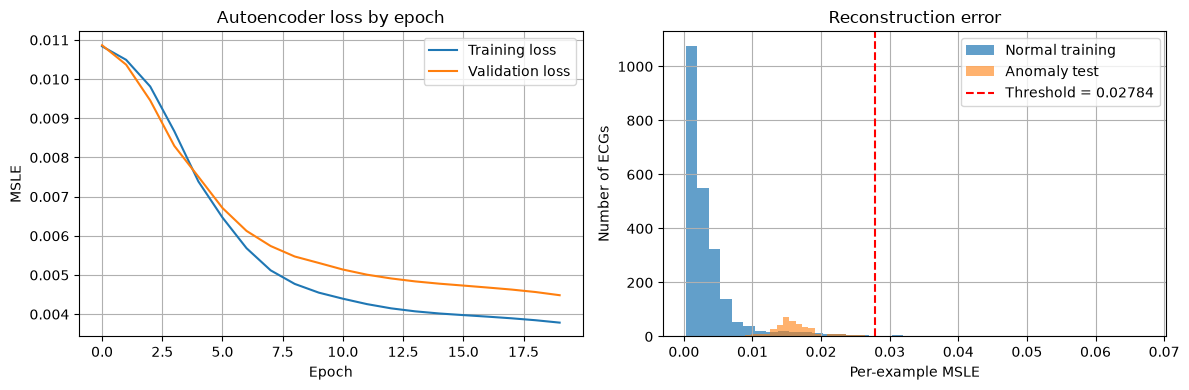

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history['loss'], label='Training loss')
axes[0].plot(history.history['val_loss'], label='Validation loss')
axes[0].set_title('Autoencoder loss by epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSLE')
axes[0].legend()
axes[0].grid(True)

axes[1].hist(train_errors, bins=40, alpha=0.7, label='Normal training')
axes[1].hist(test_errors[y_test == 0], bins=40, alpha=0.6, label='Anomaly test')
axes[1].axvline(threshold, color='red', linestyle='--', label=f'Threshold = {threshold:.4g}')
axes[1].set_title('Reconstruction error')
axes[1].set_xlabel('Per-example MSLE')
axes[1].set_ylabel('Number of ECGs')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Result

The autoencoder was trained using normal ECG examples. Test ECGs were classified as normal or anomalous according to their reconstruction error and the selected threshold. Record the threshold, test accuracy, confusion matrix, and classification report printed above.